<a href="https://colab.research.google.com/github/AmitKunduA/Class_Assignment/blob/main/Deep_Learning_and_Perceptrons.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Deep Learning and Perceptrons

## Part 1: Deep Learning vs Traditional ML

### Key Differences

| Aspect | Traditional ML | Deep Learning |
|--------|---------------|---------------|
| Features | Manual (we create them) | Automatic (model learns them) |
| Data Needed | Small datasets work | Needs large datasets |
| Training Time | Fast | Slow |
| Accuracy | Plateaus with more data | Improves with more data |

### Example: Image Recognition
- **Traditional ML:** We manually extract features (edges, colors) → Feed to classifier
- **Deep Learning:** Raw pixels → Neural network learns features automatically

> 💡 **Perceptron = Simplest neural network unit (a single neuron)**

---
## Part 2: How Perceptron Works

### Perceptron Formula
```
z = w₁×x₁ + w₂×x₂ + ... + wₙ×xₙ + b
y = activation(z)
```

**Components:**
- **x (inputs)** — Your data features
- **w (weights)** — Importance of each feature (learned by model)
- **b (bias)** — Shifts the decision boundary
- **activation** — Transforms the output (adds non-linearity)

### Why Activation Functions?
They add **non-linearity**, helping the model learn complex patterns that a straight line cannot capture.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

# Two most commonly used activation functions

def sigmoid(z):
    """Squashes output to range (0, 1) — used for binary classification."""
    return 1 / (1 + np.exp(-z))

def relu(z):
    """Passes positive values, zeros out negatives — widely used in deep networks."""
    return np.maximum(0, z)

print("✅ Activation functions defined!")

✅ Activation functions defined!


---
## Part 3: Batch vs Stochastic Gradient Descent

### Gradient Descent = The Learning Algorithm

**Weight update rule:**
```
w = w - learning_rate × gradient
```

### Two Main Types

| Method | Data Used Per Update | Advantages | Disadvantages |
|--------|----------------------|------------|---------------|
| **Batch GD** | All training data | Stable, smooth convergence | Slow, high memory usage |
| **Stochastic GD** | One sample at a time | Fast, can escape local minima | Noisy, less stable |

---
## Part 4: Simple Perceptron Implementation

Let's build a Perceptron **from scratch** — both Batch GD and Stochastic GD modes in one class.

In [11]:
class Perceptron:
    def __init__(self, lr=0.01, epochs=100, mode='batch'):
        """
        lr     : learning rate
        epochs : number of training passes
        mode   : 'batch' or 'stochastic'
        """
        self.lr     = lr
        self.epochs = epochs
        self.mode   = mode
        self.w      = None
        self.b      = None

    def _sigmoid(self, z):
        """Numerically stable sigmoid."""
        return 1 / (1 + np.exp(-np.clip(z, -500, 500)))

    def fit(self, X, y):
        X = np.asarray(X, dtype=float)   # accept DataFrame / ndarray
        y = np.asarray(y)                # accept Series / ndarray (fixes KeyError: 0)
        n, d   = X.shape
        self.w = np.zeros(d)
        self.b = 0

        for epoch in range(self.epochs):
            if self.mode == 'batch':
                # Update using ALL samples at once
                z    = X.dot(self.w) + self.b
                pred = self._sigmoid(z)
                self.w -= self.lr * X.T.dot(pred - y) / n
                self.b -= self.lr * (pred - y).mean()
            else:
                # Update ONE sample at a time
                for i in range(n):
                    z    = X[i].dot(self.w) + self.b
                    pred = self._sigmoid(z)
                    self.w -= self.lr * (pred - y[i]) * X[i]
                    self.b -= self.lr * (pred - y[i])

    def predict(self, X):
        X = np.asarray(X, dtype=float)
        return (self._sigmoid(X.dot(self.w) + self.b) >= 0.5).astype(int)


print("✅ Perceptron class defined!")

✅ Perceptron class defined!


---
## Part 5: Iris Dataset

### Task: Binary Classification — Setosa vs Others


**Kaggle Link:** https://www.kaggle.com/datasets/uciml/iris

In [ ]:
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score, confusion_matrix
import seaborn as sns

# Load dataset
iris = load_iris()
X    = iris.data
y    = (iris.target == 0).astype(int)

print(f"Total samples: {len(X)}")
print(f"Setosa: {sum(y)}, Others: {len(y) - sum(y)}")

# Train / test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=20
)

# Standardize features (important for gradient-based methods!)
scaler  = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

print("\n✅ Data ready!")

Total samples: 150
Setosa: 50, Others: 100

✅ Data ready!


In [ ]:
from sklearn.metrics import precision_score, recall_score, f1_score

# ── Train with Batch Gradient Descent ──
print("=" * 50)
print("Training with BATCH Gradient Descent")
print("=" * 50)

model_batch   = Perceptron(lr=0.1, epochs=200, mode='batch')
model_batch.fit(X_train, y_train)

y_pred_batch = model_batch.predict(X_test)
acc_batch    = accuracy_score(y_test, y_pred_batch)
prec_batch   = precision_score(y_test, y_pred_batch)
rec_batch    = recall_score(y_test, y_pred_batch)
f1_batch     = f1_score(y_test, y_pred_batch)

print(f"\nTest Accuracy : {acc_batch  * 100:.2f}%")
print(f"Precision     : {prec_batch  * 100:.2f}%")
print(f"Recall        : {rec_batch   * 100:.2f}%")
print(f"F1-Score      : {f1_batch    * 100:.2f}%")

print(f"\nCorrect: {sum(y_pred_batch == y_test)}/{len(y_test)}")

Training with BATCH Gradient Descent

Test Accuracy : 100.00%
Precision     : 100.00%
Recall        : 100.00%
F1-Score      : 100.00%

Correct: 30/30


In [ ]:
# ── Train with Stochastic Gradient Descent ──
print("=" * 50)
print("Training with STOCHASTIC Gradient Descent")
print("=" * 50)

model_sgd   = Perceptron(lr=0.1, epochs=200, mode='stochastic')
model_sgd.fit(X_train, y_train)

y_pred_sgd = model_sgd.predict(X_test)
acc_sgd    = accuracy_score(y_test, y_pred_sgd)
prec_sgd   = precision_score(y_test, y_pred_sgd)
rec_sgd    = recall_score(y_test, y_pred_sgd)
f1_sgd     = f1_score(y_test, y_pred_sgd)

print(f"\nTest Accuracy : {acc_sgd  * 100:.2f}%")
print(f"Precision     : {prec_sgd  * 100:.2f}%")
print(f"Recall        : {rec_sgd   * 100:.2f}%")
print(f"F1-Score      : {f1_sgd    * 100:.2f}%")
print(f"\nCorrect: {sum(y_pred_sgd == y_test)}/{len(y_test)}")

Training with STOCHASTIC Gradient Descent

Test Accuracy : 100.00%
Precision     : 100.00%
Recall        : 100.00%
F1-Score      : 100.00%

Correct: 30/30


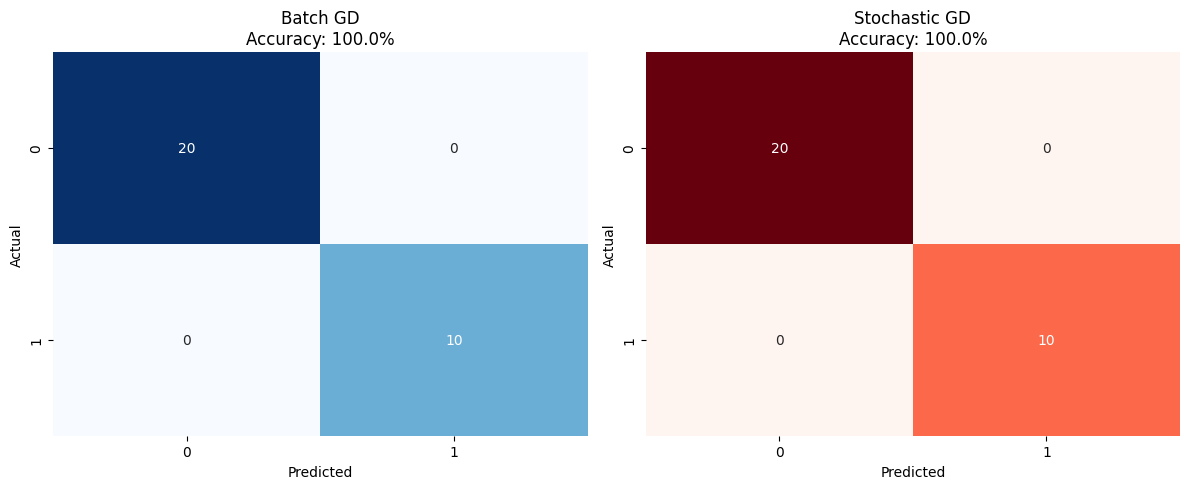


COMPARISON: Batch GD vs Stochastic GD
Metric                           Batch GD        Stochastic GD
----------------------------------------------------------------------
Accuracy                          100.00%              100.00%
Precision                         100.00%              100.00%
Recall                            100.00%              100.00%
F1-Score                          100.00%              100.00%
✅ Training complete!


In [ ]:
# ── Visualize: Confusion Matrices side by side ──

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

cm_batch = confusion_matrix(y_test, y_pred_batch)
sns.heatmap(cm_batch, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False)
axes[0].set_title(f'Batch GD\nAccuracy: {acc_batch * 100:.1f}%', fontsize=12)
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

cm_sgd = confusion_matrix(y_test, y_pred_sgd)
sns.heatmap(cm_sgd, annot=True, fmt='d', cmap='Reds', ax=axes[1], cbar=False)
axes[1].set_title(f'Stochastic GD\nAccuracy: {acc_sgd * 100:.1f}%', fontsize=12)
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()

# ── Print comparison table ──
print("\n" + "=" * 70)
print("COMPARISON: Batch GD vs Stochastic GD")
print("=" * 70)
print(f"{'Metric':<20} {'Batch GD':>20} {'Stochastic GD':>20}")
print("-" * 70)
print(f"{'Accuracy':<20} {acc_batch  * 100:>19.2f}% {acc_sgd  * 100:>19.2f}%")
print(f"{'Precision':<20} {prec_batch * 100:>19.2f}% {prec_sgd * 100:>19.2f}%")
print(f"{'Recall':<20} {rec_batch  * 100:>19.2f}% {rec_sgd  * 100:>19.2f}%")
print(f"{'F1-Score':<20} {f1_batch   * 100:>19.2f}% {f1_sgd   * 100:>19.2f}%")
print("=" * 70)
print("✅ Training complete!")
print("=" * 70)

---
## Key Observations

### Batch GD
- **Stable** training — gradients are averaged over all data
- **Predictable** convergence — smooth loss curve
- **Slower** per epoch — processes all data before updating

### Stochastic GD
- **Fast** per update — one sample at a time
- Can **escape local minima** due to noisy updates
- **Noisier** convergence — zigzags toward the minimum

---

### Understanding the Metrics

> **Why not just use Accuracy?**  
> Accuracy can be misleading, especially with **imbalanced data**!

| Metric | Formula | Meaning |
|--------|---------|----------|
| **Precision** | `TP / (TP + FP)` | Of all predicted positives, how many are correct? |
| **Recall** | `TP / (TP + FN)` | Of all actual positives, how many did we catch? |
| **F1-Score** | `2 × (P × R) / (P + R)` | Harmonic mean of Precision and Recall |


## Part 6: Dataset Credit Card Fraud Detection

**Dataset:** [Kaggle — Credit Card Fraud Detection](https://www.kaggle.com/datasets/mlg-ulb/creditcardfraud)


In [1]:
import time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,confusion_matrix

from google.colab import drive
drive.mount("/content/drive")

Mounted at /content/drive


In [2]:
df = pd.read_csv("/content/drive/MyDrive/python/creditcard.csv")
display(df.head())

print("Shape:", df.shape)
print("\nMissing values per column:", df.isnull().sum().sum())

print("\nClass distribution:")
print(df["Class"].value_counts())
print(f"Fraud percentage: {df['Class'].mean() * 100:.3f}%")


,Time,V1,V2,V3,V4,V5,V6,V7,V8,V9,...,V21,V22,V23,V24,V25,V26,V27,V28,Amount,Class
0,0.0,-1.359807,-0.072781,2.536347,1.378155,-0.338321,0.462388,0.239599,0.098698,0.363787,...,-0.018307,0.277838,-0.110474,0.066928,0.128539,-0.189115,0.133558,-0.021053,149.62,0
1,0.0,1.191857,0.266151,0.166480,0.448154,0.060018,-0.082361,-0.078803,0.085102,-0.255425,...,-0.225775,-0.638672,0.101288,-0.339846,0.167170,0.125895,-0.008983,0.014724,2.69,0
2,1.0,-1.358354,-1.340163,1.773209,0.379780,-0.503198,1.800499,0.791461,0.247676,-1.514654,...,0.247998,0.771679,0.909412,-0.689281,-0.327642,-0.139097,-0.055353,-0.059752,378.66,0
3,1.0,-0.966272,-0.185226,1.792993,-0.863291,-0.010309,1.247203,0.237609,0.377436,-1.387024,...,-0.108300,0.005274,-0.190321,-1.175575,0.647376,-0.221929,0.062723,0.061458,123.50,0
4,2.0,-1.158233,0.877737,1.548718,0.403034,-0.407193,0.095921,0.592941,-0.270533,0.817739,...,-0.009431,0.798278,-0.137458,0.141267,-0.206010,0.502292,0.219422,0.215153,69.99,0


Shape: (284807, 31)

Missing values per column: 0

Class distribution:
Class
0    284315
1       492
Name: count, dtype: int64
Fraud percentage: 0.173%


In [3]:
# Handle missing values (this dataset has none, but we drop any just in case)
df = df.dropna()

X = df.drop(columns="Class")
y = df["Class"].astype(int)

print(f"Total Sample: {len(X)}")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=20
)

scaler  = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test  = scaler.transform(X_test)

print("\n✅ Data ready!")


Total Sample: 284807

✅ Data ready!


In [13]:
print("=" * 50)
print("Training with BATCH Gradient Descent")
print("=" * 50)

t0 = time.time()
model_bat = Perceptron(lr=0.1, mode='batch', epochs=1000)
model_bat.fit(X_train, y_train)
time_bat = time.time() - t0

y_pred_bat = model_bat.predict(X_test)
acc_bat = accuracy_score(y_test, y_pred_bat)
pre_bat = precision_score(y_test, y_pred_bat)
rec_bat = recall_score(y_test, y_pred_bat)
f1_bat  = f1_score(y_test, y_pred_bat)

print(f"Training time : {time_bat:.2f}s")
print(f"Test Accuracy : {acc_bat * 100:.2f}%")
print(f"Precision     : {pre_bat * 100:.2f}%")
print(f"Recall        : {rec_bat * 100:.2f}%")
print(f"F1-score      : {f1_bat * 100:.2f}%")

print(f"\nCorrect: {sum(y_pred_bat == y_test)}/{len(y_test)}")


Training with BATCH Gradient Descent
Training time : 8.67s
Test Accuracy : 99.91%
Precision     : 85.71%
Recall        : 55.10%
F1-score      : 67.08%

Correct: 56909/56962


In [14]:
print("=" * 50)
print("Training with STOCHASTIC Gradient Descent")
print("=" * 50)

# SGD does one update per sample (~228k updates per epoch), so a few epochs are enough
t0 = time.time()
model_stc = Perceptron(lr=0.01, mode='stochastic', epochs=3)
model_stc.fit(X_train, y_train)
time_stc = time.time() - t0

y_pred_stc = model_stc.predict(X_test)
acc_stc = accuracy_score(y_test, y_pred_stc)
pre_stc = precision_score(y_test, y_pred_stc)
rec_stc = recall_score(y_test, y_pred_stc)
f1_stc  = f1_score(y_test, y_pred_stc)

print(f"Training time : {time_stc:.2f}s")
print(f"Test Accuracy : {acc_stc * 100:.2f}%")
print(f"Precision     : {pre_stc * 100:.2f}%")
print(f"Recall        : {rec_stc * 100:.2f}%")
print(f"F1-score      : {f1_stc * 100:.2f}%")

print(f"\nCorrect: {sum(y_pred_stc == y_test)}/{len(y_test)}")


Training with STOCHASTIC Gradient Descent
Training time : 5.11s
Test Accuracy : 99.93%
Precision     : 81.25%
Recall        : 79.59%
F1-score      : 80.41%

Correct: 56924/56962


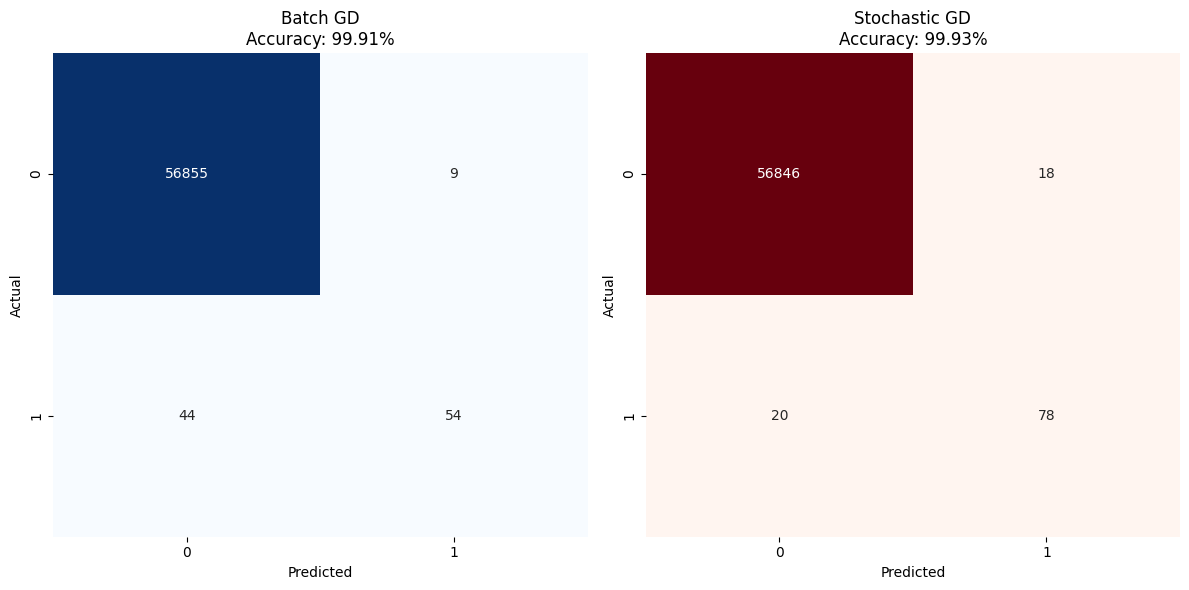

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 6))

cm_bat = confusion_matrix(y_test, y_pred_bat)
sns.heatmap(cm_bat, annot=True, fmt='d', cmap='Blues', ax=axes[0], cbar=False)
axes[0].set_title(f"Batch GD\nAccuracy: {acc_bat * 100:.2f}%", fontsize=12)
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

cm_stc = confusion_matrix(y_test, y_pred_stc)
sns.heatmap(cm_stc, annot=True, fmt='d', cmap='Reds', ax=axes[1], cbar=False)
axes[1].set_title(f"Stochastic GD\nAccuracy: {acc_stc * 100:.2f}%", fontsize=12)
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()


## Observation

### Recall is important for fraud detection because credit card fraud dataset are heavily imbalanced, where fraudulent transictions represent only a tiny fraction of the total data.High recall ensure that the model successfully catches as many actual fraudulent cases as possible.